# IT2226 – ShopSphere: Data Cleaning & EDA
**Files covered:** `customers.csv`, `customer_preferences.csv`, `train.csv`, `test.csv`

**Goal:** profile the four files, find and document every data-quality issue, clean them, and explore how the cleaned features relate to the target (`1` = purchased between 1 and 30 Oct 2024).

**Cleaning policy (decided with the team):**
- Fix *format* problems now (spellings, text-to-number, dates, true/false encodings).
- **Do not impute** missing values. Missing `age` and `email_open_rate` stay empty and get an `*_is_missing` indicator column. Imputation belongs *inside* the modelling pipeline, fitted on the training folds only, so that nothing from validation or test data leaks into training.
- **One deliberate exception:** impossible review scores above 5 (scale maximum) are **capped to 5.0**, without a flag. Section 6.4b shows the evidence and the trade-off.
- Other oddities (pile-ups on 2022-01-01 and 2024-09-30, preferred channel without opt-in) are **kept as they are**. They are documented here and computed on the fly for EDA, but no extra columns are saved.
- The original data pack is never modified. Cleaned copies go to a separate folder.

**Sections**
1. Setup  2. Load raw data  3. Profile (data quality audit)  4. Cleaning  5. Validation of cleaned data  6. EDA  7. Train vs test shift check  8. Save outputs, summary

## 1. Setup

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# ---- Paths ----------------------------------------------------------------
# On Google Colab: upload the data pack to Google Drive, then edit DRIVE_DATA_DIR below.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DATA_DIR = "/content/drive/MyDrive/IT2226/data_pack"   # <-- EDIT THIS
    DATA_DIR = DRIVE_DATA_DIR
    OUT_DIR = "/content/drive/MyDrive/IT2226/cleaned"             # cleaned CSVs + figures go here
else:
    DATA_DIR = os.environ.get("DATA_DIR", "./data_pack")
    OUT_DIR = os.environ.get("OUT_DIR", "./cleaned")

FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

CUTOFF = pd.Timestamp("2024-09-30")      # data snapshot date (DATA_README.md)
HISTORY_START = pd.Timestamp("2022-01-01")
SEED = 42
KEEP_NOISE_COLUMNS = False               # noise_customer_0-4 have no business meaning; tested in section 6.6

SUMMARY = {}                              # key numbers collected here are re-used in the Word report

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

print("DATA_DIR:", DATA_DIR); print("OUT_DIR :", OUT_DIR)

DATA_DIR: ./data_pack
OUT_DIR : ./cleaned


## 2. Load raw data
Everything is read as **text** (`dtype=str`, `keep_default_na=False`) first. This is deliberate: it lets us see the data exactly as exported (blank cells, mixed spellings, `$` signs) before pandas silently converts anything.

In [2]:
def read_raw(name):
    return pd.read_csv(os.path.join(DATA_DIR, name), dtype=str, keep_default_na=False)

raw_customers = read_raw("customers.csv")
raw_prefs     = read_raw("customer_preferences.csv")
raw_train     = read_raw("train.csv")
raw_test      = read_raw("test.csv")

for n, d in [("customers", raw_customers), ("customer_preferences", raw_prefs), ("train", raw_train), ("test", raw_test)]:
    print(f"{n:22s} rows={len(d):>7,}  cols={d.shape[1]}")
SUMMARY["rows"] = {"customers": len(raw_customers), "preferences": len(raw_prefs), "train": len(raw_train), "test": len(raw_test)}
raw_customers.head()

customers              rows= 80,000  cols=17
customer_preferences   rows= 80,000  cols=7
train                  rows= 64,000  cols=2
test                   rows= 16,000  cols=1


,customer_id,age,country_code,region,signup_date,loyalty_score,email_open_rate,discount_usage_rate,avg_review_score,referral_code,customer_tier,credit_limit,noise_customer_0,noise_customer_1,noise_customer_2,noise_customer_3,noise_customer_4
0,0,51,DE,region_70,2022-01-01,0.248,0.2344748049158769,0.0,4.21,REF_702384,Bronze,"$17,757",-0.2412205570670695,-0.850325716147161,-0.03924410442503535,0.36815500722393885,-1.6466640294631665
1,1,39,USA,region_38,2022-01-01,0.077,0.6100785362092823,0.252,3.87,REF_433919,Bronze,"$3,424",-1.3647259827274356,0.25244318898685997,-0.5319154909351118,1.112297343029753,-0.4135985488105785
2,2,56,UK,region_44,2024-03-14,0.16,0.46613101245612865,0.023,4.74,REF_684399,Bronze,"$13,373",0.24310804569208358,0.06856285741074698,0.3836869057522753,0.6223932971720098,-0.9076834913654365
3,3,29,uk,region_56,2024-05-02,0.163,0.482747118039523,0.0,4.07,REF_257492,Silver,"$18,995",0.44948352408147274,0.8523896995245943,0.9835349772669785,-0.9332526264738878,0.44514107819160426
4,4,44,FR,region_85,2023-05-25,0.133,0.20602983790803583,0.351,3.34,REF_404224,Bronze,"$11,074",-0.7043796896324787,-0.8574343194958594,-2.3116777827135344,0.4899588843209814,2.232989920154349


## 3. Profile the raw data (data-quality audit)
We check, for every file: duplicates, key integrity between files, blanks, inconsistent categories, numbers stored as text, out-of-range values and impossible dates.

### 3.1 Keys, duplicates and linkage between files

In [3]:
tr_ids, te_ids = set(raw_train.customer_id), set(raw_test.customer_id)
cu_ids, pr_ids = set(raw_customers.customer_id), set(raw_prefs.customer_id)

checks = {
    "customers: duplicate customer_id":            int(raw_customers.customer_id.duplicated().sum()),
    "customers: fully duplicated rows":            int(raw_customers.duplicated().sum()),
    "preferences: duplicate customer_id":          int(raw_prefs.customer_id.duplicated().sum()),
    "train: duplicate customer_id":                int(raw_train.customer_id.duplicated().sum()),
    "test: duplicate customer_id":                 int(raw_test.customer_id.duplicated().sum()),
    "train ∩ test customer_ids (should be 0)":     len(tr_ids & te_ids),
    "train ids missing from customers":            len(tr_ids - cu_ids),
    "test ids missing from customers":             len(te_ids - cu_ids),
    "preferences ids missing from customers":      len(pr_ids - cu_ids),
    "customers without a preferences row":         len(cu_ids - pr_ids),
    "customers in neither train nor test":         len(cu_ids - tr_ids - te_ids),
    "train targets not in {0,1}":                  int((~raw_train.target.isin(["0","1"])).sum()),
}
audit_keys = pd.Series(checks, name="count").to_frame()
SUMMARY["key_checks"] = checks
audit_keys

,count
customers: duplicate customer_id,0
customers: fully duplicated rows,0
preferences: duplicate customer_id,0
train: duplicate customer_id,0
test: duplicate customer_id,0
train ∩ test customer_ids (should be 0),0
train ids missing from customers,0
test ids missing from customers,0
preferences ids missing from customers,0
customers without a preferences row,0


**Reading:** keys are clean. No duplicate IDs, train/test are disjoint, and every customer appears in exactly one of train/test and has exactly one preferences row. So `train + test = customers` (64,000 + 16,000 = 80,000) and joins will be 1-to-1 with no row loss. The mess is inside the columns, not the keys.

### 3.2 Blanks, text-stored numbers and category spellings

In [4]:
blank = (raw_customers == "").sum().rename("blank_cells").to_frame()
blank["pct"] = (blank.blank_cells / len(raw_customers) * 100).round(2)
print("customers.csv blanks"); display(blank[blank.blank_cells > 0])
print("customer_preferences.csv blanks:", int((raw_prefs == "").sum().sum()))

print("\ncountry_code spellings (raw):"); display(raw_customers.country_code.value_counts().rename("n").to_frame().T)
print("age values that are not numeric:", raw_customers.age[~raw_customers.age.str.fullmatch(r"\d+")].value_counts().to_dict())
print("credit_limit examples:", raw_customers.credit_limit.head(5).tolist(), "<- stored as text with $ and commas")
print("\npreferences categories:")
for col in ["email_opt_in", "sms_opt_in", "do_not_contact", "preferred_channel", "preferred_language"]:
    print(f"  {col:20s}", raw_prefs[col].value_counts().to_dict())
SUMMARY["raw_country_spellings"] = raw_customers.country_code.value_counts().to_dict()
SUMMARY["email_open_rate_blank"] = int((raw_customers.email_open_rate == "").sum())
SUMMARY["age_unknown"] = int((raw_customers.age == "unknown").sum())

customers.csv blanks


,blank_cells,pct
email_open_rate,14559,18.2


customer_preferences.csv blanks: 0

country_code spellings (raw):


country_code,U.S.,USA,usa,US,UK,GB,uk,DE,de,Germany,fr,FR,IN,India,in
n,8094,8007,7967,7888,5391,5346,5338,5286,5278,5258,4105,3991,2723,2680,2648


age values that are not numeric: {'unknown': 4119}
credit_limit examples: ['$17,757', '$3,424', '$13,373', '$18,995', '$11,074'] <- stored as text with $ and commas

preferences categories:
  email_opt_in         {'Y': 54414, 'N': 25586}
  sms_opt_in           {'N': 52383, 'Y': 27617}
  do_not_contact       {'N': 78366, 'Y': 1634}
  preferred_channel    {'email': 39995, 'app_push': 20056, 'sms': 11990, 'whatsapp': 7959}
  preferred_language   {'en': 52028, 'de': 15822, 'fr': 8096, 'hi': 4054}


**Reading:**
- `country_code` has **15 spellings for 5 countries** (e.g. `U.S.`, `USA`, `usa`, `US` all mean the United States). Left alone, a model would treat them as 15 different groups.
- `age` mixes numbers with the word `unknown`; `credit_limit` is text like `$17,757`.
- `email_open_rate` is the only column with blanks (about 18%).
- `customer_preferences.csv` is already consistent (clean `Y/N`, four channels, four languages). The README lists several true/false encodings, but they occur in other tables, not this one.

### 3.3 Out-of-range values and impossible dates

In [5]:
num = lambda s: pd.to_numeric(s.replace("", np.nan), errors="coerce")

rng = {}
for col, lo, hi in [("loyalty_score", 0, 1), ("email_open_rate", 0, 1), ("discount_usage_rate", 0, 1), ("avg_review_score", 1, 5)]:
    s = num(raw_customers[col])
    rng[col] = {"min": s.min(), "max": s.max(), "below_range": int((s < lo).sum()), "above_range": int((s > hi).sum())}
age_n = num(raw_customers.age)
rng["age"] = {"min": age_n.min(), "max": age_n.max(), "below_range": int((age_n < 18).sum()), "above_range": int((age_n > 100).sum())}
display(pd.DataFrame(rng).T)

sd = pd.to_datetime(raw_customers.signup_date, errors="coerce")
lu = pd.to_datetime(raw_prefs.last_updated, errors="coerce")
print("unparseable signup_date:", int(sd.isna().sum()), "| signup after cutoff:", int((sd > CUTOFF).sum()))
print("unparseable last_updated:", int(lu.isna().sum()), "| last_updated after cutoff:", int((lu > CUTOFF).sum()))
print("signup_date == 2022-01-01 (first day of history):", int((sd == HISTORY_START).sum()))
print("last_updated == 2024-09-30 (the cutoff day):", int((lu == CUTOFF).sum()))
SUMMARY["avg_review_gt5"] = int((num(raw_customers.avg_review_score) > 5).sum())
SUMMARY["avg_review_eq5"] = int((num(raw_customers.avg_review_score) == 5).sum())
SUMMARY["avg_review_max"] = float(num(raw_customers.avg_review_score).max())
SUMMARY["signup_on_history_start"] = int((sd == HISTORY_START).sum())
SUMMARY["pref_updated_on_cutoff"] = int((lu == CUTOFF).sum())

,min,max,below_range,above_range
loyalty_score,0.009000,0.961000,0.0,0.0
email_open_rate,0.000013,0.977283,0.0,0.0
discount_usage_rate,0.000000,1.000000,0.0,0.0
avg_review_score,1.510000,6.500000,0.0,313.0
age,18.000000,78.000000,0.0,0.0


unparseable signup_date: 0 | signup after cutoff: 0
unparseable last_updated: 0 | last_updated after cutoff: 0
signup_date == 2022-01-01 (first day of history): 14122
last_updated == 2024-09-30 (the cutoff day): 14005


**Reading:**
- `avg_review_score` should be 1 to 5 but reaches **6.5** (313 customers above 5). These are impossible values.
- **14,122 customers have `signup_date = 2022-01-01`**, against roughly 1,100 to 2,600 per month afterwards (rising over time; chart below). The data only starts on that date, so these are almost certainly customers who signed up *on or before* it (left-censored), not people who all joined on one day.
- **14,005 preference rows have `last_updated = 2024-09-30`**, the cutoff date. Same pattern: a pile-up on a boundary date, probably values clipped to the snapshot date.
- No dates are unparseable or after the cutoff, so there is no future-dated leakage.

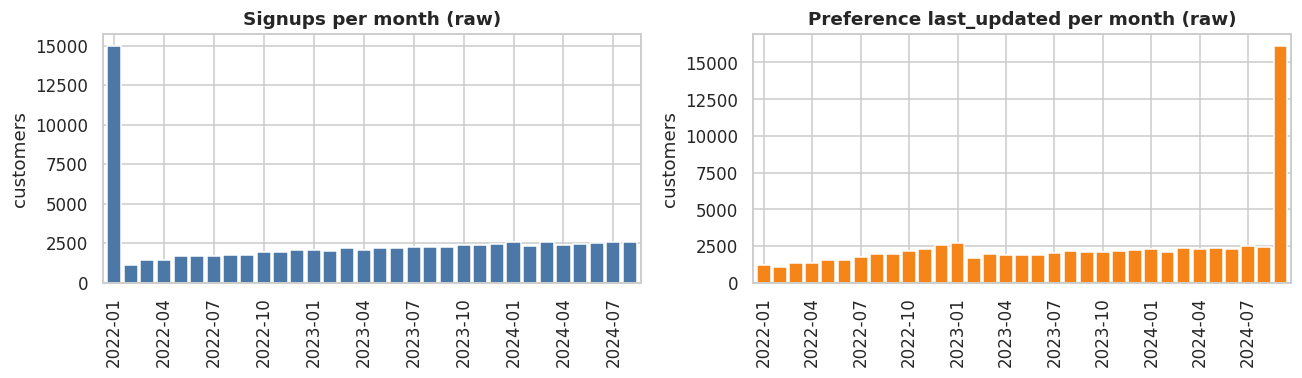

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sd.dt.to_period("M").value_counts().sort_index().plot(ax=ax[0], kind="bar", color="#4C78A8", width=0.85)
ax[0].set_title("Signups per month (raw)"); ax[0].set_xlabel(""); ax[0].set_ylabel("customers")
ax[0].set_xticks(ax[0].get_xticks()[::3])
lu.dt.to_period("M").value_counts().sort_index().plot(ax=ax[1], kind="bar", color="#F58518", width=0.85)
ax[1].set_title("Preference last_updated per month (raw)"); ax[1].set_xlabel(""); ax[1].set_ylabel("customers")
ax[1].set_xticks(ax[1].get_xticks()[::3])
savefig("fig01_date_pileups")

### 3.3b Pile-ups at the edges of a range

In [7]:
cu = raw_customers.assign(age_n=num(raw_customers.age), dur=num(raw_customers.discount_usage_rate), ars=num(raw_customers.avg_review_score))
edge = pd.Series({
    "age = 18 (youngest allowed)":                 int((cu.age_n == 18).sum()),
    "age = 19 (for comparison)":                   int((cu.age_n == 19).sum()),
    "age = 20 (for comparison)":                   int((cu.age_n == 20).sum()),
    "avg_review_score = 5.0 (scale maximum)":      int((cu.ars == 5).sum()),
    "discount_usage_rate = 0 (never used a discount)": int((cu.dur == 0).sum()),
    "discount_usage_rate = 1 (always used a discount)": int((cu.dur == 1).sum()),
}, name="customers")
display(edge.to_frame())
SUMMARY["age_eq_18"] = int((cu.age_n == 18).sum()); SUMMARY["age_eq_19"] = int((cu.age_n == 19).sum())
SUMMARY["dur_eq_0"] = int((cu.dur == 0).sum()); SUMMARY["dur_eq_1"] = int((cu.dur == 1).sum())

,customers
age = 18 (youngest allowed),5125
age = 19 (for comparison),823
age = 20 (for comparison),889
avg_review_score = 5.0 (scale maximum),5379
discount_usage_rate = 0 (never used a discount),16799
discount_usage_rate = 1 (always used a discount),6044


**Reading:** these spikes look like values squeezed against a limit, but they are **not all errors**:
- **Age 18: 5,125 customers**, versus about 850 at ages 19 and 20. Ages below 18 were probably raised to 18. We keep the values and treat age as an approximate field (bin it, or add an "age = 18" indicator) rather than changing it.
- **Review score = 5.0: 5,379 customers** (6.7%), the scale maximum. The 313 values *above* 5 are the real errors (we cap them to 5.0, see section 4.1); exact 5.0 is a legitimate top score.
- **Discount usage rate = 0 (21%) and = 1 (7.6%)** are plausible, since it is a share of a customer's orders and customers with few orders will often be exactly 0 or 1. No change.

### 3.4 Do the preference fields contradict each other?

In [8]:
p = raw_prefs.copy()
print("do_not_contact = Y vs opt-ins:")
display(pd.crosstab(p.do_not_contact, [p.email_opt_in, p.sms_opt_in], rownames=["do_not_contact"], colnames=["email_opt_in", "sms_opt_in"]))

conflict_email = (p.preferred_channel == "email") & (p.email_opt_in == "N")
conflict_sms   = (p.preferred_channel == "sms")   & (p.sms_opt_in == "N")
print("preferred_channel = email but email_opt_in = N :", int(conflict_email.sum()))
print("preferred_channel = sms   but sms_opt_in   = N :", int(conflict_sms.sum()))
print("combined: %d customers (%.1f%%)" % ((conflict_email | conflict_sms).sum(), (conflict_email | conflict_sms).mean() * 100))
SUMMARY["channel_conflict"] = int((conflict_email | conflict_sms).sum())
SUMMARY["channel_conflict_email"] = int(conflict_email.sum()); SUMMARY["channel_conflict_sms"] = int(conflict_sms.sum())
SUMMARY["dnc_yes"] = int((p.do_not_contact == "Y").sum())

do_not_contact = Y vs opt-ins:


email_opt_in        N            Y       
sms_opt_in          N     Y      N      Y
do_not_contact                           
N               15517  8435  35232  19182
Y                1634     0      0      0

preferred_channel = email but email_opt_in = N : 12792
preferred_channel = sms   but sms_opt_in   = N : 7803
combined: 20595 customers (25.7%)


**Reading:**
- All 1,634 `do_not_contact = Y` customers also have both opt-ins set to `N`, so those fields agree.
- But about **a quarter of customers list a preferred channel they have not opted in to** (e.g. prefer email, `email_opt_in = N`). This is not a spelling error, so we **do not change it**. It is a consent risk: any agent that picks a channel from `preferred_channel` alone could contact someone without consent (wish **W4**). We keep it unchanged (no extra column is saved), compute the flag on the fly for EDA, and carry the finding into the report.
- `app_push` and `whatsapp` have no opt-in column at all, so consent for those channels cannot be checked from these files.

## 4. Cleaning
Each step is a small function so it is easy to explain, test and re-run. Every change is also written to a **cleaning log** (section 4.3).

In [9]:
CLEAN_LOG = []
def log(file, column, issue, action, n_affected, note=""):
    CLEAN_LOG.append({"file": file, "column": column, "issue": issue, "action": action, "rows_affected": int(n_affected), "note": note})

COUNTRY_MAP = {"us": "US", "usa": "US", "u.s.": "US",
               "uk": "UK", "gb": "UK",
               "de": "DE", "germany": "DE",
               "fr": "FR",
               "in": "IN", "india": "IN"}

### 4.1 `customers.csv`

In [10]:
def clean_customers(raw: pd.DataFrame, keep_noise=False) -> pd.DataFrame:
    df = raw.copy()
    df = df.apply(lambda s: s.str.strip())                      # remove stray whitespace everywhere
    df["customer_id"] = df.customer_id.astype(int)

    # country_code: 15 spellings -> 5 codes, standardised in place (the column keeps its name)
    mapped = df.country_code.str.lower().map(COUNTRY_MAP)
    assert mapped.notna().all(), "unmapped country spelling found"
    log("customers", "country_code", "15 inconsistent spellings of 5 countries", "standardised in place to US/UK/DE/FR/IN", (df.country_code != mapped).sum())
    df["country_code"] = mapped

    # age: 'unknown' -> NaN + indicator (no imputation)
    age = pd.to_numeric(df.age, errors="coerce")
    df["age_is_missing"] = age.isna().astype(int)
    log("customers", "age", "text value 'unknown'", "set to NaN, added age_is_missing", age.isna().sum())
    log("customers", "age", "pile-up at 18 (about 6x the count at ages 19 and 20)", "kept as-is, no flag (documented in section 3.3b)", (age == 18).sum())
    df["age"] = age

    # signup_date: text -> date
    df["signup_date"] = pd.to_datetime(df.signup_date)
    log("customers", "signup_date", "pile-up on 2022-01-01, the first day of history (probably left-censored)", "kept as-is, no flag (EDA computes signup_before_history_flag on the fly)", (df.signup_date == HISTORY_START).sum())

    # numeric columns stored as text
    for c in ["loyalty_score", "email_open_rate", "discount_usage_rate", "avg_review_score"]:
        df[c] = pd.to_numeric(df[c].replace("", np.nan), errors="coerce")

    df["email_open_rate_is_missing"] = df.email_open_rate.isna().astype(int)
    log("customers", "email_open_rate", "blank values", "left as NaN, added email_open_rate_is_missing (impute in the pipeline)", df.email_open_rate_is_missing.sum())

    # avg_review_score: impossible values above the 1-5 scale are capped to the scale maximum (team decision, no flag)
    over5 = df.avg_review_score > 5
    df.loc[over5, "avg_review_score"] = 5.0
    log("customers", "avg_review_score", "values above 5 on a 1-5 scale (max 6.5)", "capped to 5.0 (scale maximum); no flag", over5.sum(),
        note="Alternative considered: set to missing plus a flag. Rejected because the raw data already piles up at exactly 5.0, so values above 5 look like clipped top scores, and median imputation would probably understate them (section 6.4b). Trade-off: the capped rows can no longer be identified in the cleaned file.")

    # credit_limit: '$17,757' -> 17757.0
    df["credit_limit"] = pd.to_numeric(df.credit_limit.str.replace(r"[$,]", "", regex=True), errors="coerce").astype(float)   # float (17757.0)
    log("customers", "credit_limit", "numbers stored as text with $ and commas", "converted to float", len(df))

    # referral_code: duplicates look like random collisions, not duplicate people
    shared = df.referral_code.duplicated(keep=False)
    log("customers", "referral_code", "code shared by 2+ customers (about what random 6-digit codes give by chance)", "kept as-is, no flag (identifier, not a model feature)", shared.sum())

    # tier as ordered category in memory (saved as text)
    df["customer_tier"] = pd.Categorical(df.customer_tier, ["Bronze", "Silver", "Gold", "Platinum"], ordered=True)

    noise = [c for c in df.columns if c.startswith("noise_customer_")]
    if keep_noise:
        df[noise] = df[noise].astype(float)
    else:
        df = df.drop(columns=noise)
    log("customers", "noise_customer_0-4", "system fields with no business meaning", "dropped from the saved file after confirming no signal (section 6.6)", len(df))

    order = ["customer_id", "age", "country_code", "region", "signup_date", "loyalty_score", "email_open_rate", "discount_usage_rate",
             "avg_review_score", "referral_code", "customer_tier", "credit_limit", "age_is_missing", "email_open_rate_is_missing"] + [c for c in df.columns if c.startswith("noise_")]
    return df[order]

customers = clean_customers(raw_customers, keep_noise=True)   # keep noise for now so section 6.6 can test it
customers.dtypes.to_frame("dtype").T

,customer_id,age,country_code,region,signup_date,loyalty_score,email_open_rate,discount_usage_rate,avg_review_score,referral_code,customer_tier,credit_limit,age_is_missing,email_open_rate_is_missing,noise_customer_0,noise_customer_1,noise_customer_2,noise_customer_3,noise_customer_4
dtype,int64,float64,str,str,datetime64[us],float64,float64,float64,float64,str,category,float64,int64,int64,float64,float64,float64,float64,float64


We keep the noise columns in memory for now so section 6.6 can *prove* they carry no signal before we drop them from the saved file.

**Why cap instead of set to missing?** The scale is 1 to 5, and 5,379 customers already sit at exactly 5.0 in the raw data, so the source appears to clip at 5. The 313 values above 5 (mean about 5.8) look like top scorers who escaped the clip. Section 6.4b compares their purchase rate with customers at exactly 5.0 to test this.

**No derived or extra flag columns are saved.** Quantities such as tenure and consent conflicts are still computed, but only inside the EDA (section 6), so the saved files contain no EDA-only columns.

### 4.2 `customer_preferences.csv`, `train.csv`, `test.csv`

In [11]:
def clean_preferences(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy().apply(lambda s: s.str.strip())
    df["customer_id"] = df.customer_id.astype(int)
    for c in ["email_opt_in", "sms_opt_in", "do_not_contact"]:
        assert df[c].isin(["Y", "N"]).all(), f"unexpected values in {c}"
        df[c] = (df[c] == "Y").astype(int)
    log("preferences", "email_opt_in / sms_opt_in / do_not_contact", "Y/N text", "converted to 1/0", len(df))

    df["preferred_channel"] = df.preferred_channel.str.lower()
    df["preferred_language"] = df.preferred_language.str.lower()
    df["last_updated"] = pd.to_datetime(df.last_updated)
    log("preferences", "last_updated", "pile-up on the cutoff date 2024-09-30 (probably clipped)", "kept as-is, no flag (EDA computes pref_updated_on_cutoff_flag on the fly)", (df.last_updated == CUTOFF).sum())

    conflict = (((df.preferred_channel == "email") & (df.email_opt_in == 0)) | ((df.preferred_channel == "sms") & (df.sms_opt_in == 0)))
    log("preferences", "preferred_channel", "preferred email/sms channel without matching opt-in (consent risk, W4)", "kept as-is, no flag (EDA computes channel_consent_conflict_flag on the fly)", conflict.sum())
    return df[["customer_id", "email_opt_in", "sms_opt_in", "preferred_channel", "preferred_language", "do_not_contact", "last_updated"]]

def clean_ids(raw: pd.DataFrame, has_target: bool) -> pd.DataFrame:
    df = raw.copy().apply(lambda s: s.str.strip())
    df["customer_id"] = df.customer_id.astype(int)
    if has_target:
        assert df.target.isin(["0", "1"]).all()
        df["target"] = df.target.astype(int)
    log("train" if has_target else "test", "customer_id" + ("/target" if has_target else ""), "none found (validated)", "cast to int", len(df))
    return df

preferences = clean_preferences(raw_prefs)
train = clean_ids(raw_train, True)
test  = clean_ids(raw_test, False)
preferences.head()

,customer_id,email_opt_in,sms_opt_in,preferred_channel,preferred_language,do_not_contact,last_updated
0,0,0,1,email,de,0,2022-10-13
1,1,1,1,app_push,en,0,2022-02-19
2,2,1,1,email,en,0,2024-06-15
3,3,1,1,email,en,0,2024-09-30
4,4,0,1,email,fr,0,2023-05-30


### 4.3 Cleaning log

In [12]:
cleaning_log = pd.DataFrame(CLEAN_LOG)
pd.set_option("display.max_colwidth", 120)
cleaning_log

,file,column,issue,action,rows_affected,note
0,customers,country_code,15 inconsistent spellings of 5 countries,standardised in place to US/UK/DE/FR/IN,54721,
1,customers,age,text value 'unknown',"set to NaN, added age_is_missing",4119,
2,customers,age,pile-up at 18 (about 6x the count at ages 19 and 20),"kept as-is, no flag (documented in section 3.3b)",5125,
3,customers,signup_date,"pile-up on 2022-01-01, the first day of history (probably left-censored)","kept as-is, no flag (EDA computes signup_before_history_flag on the fly)",14122,
4,customers,email_open_rate,blank values,"left as NaN, added email_open_rate_is_missing (impute in the pipeline)",14559,
5,customers,avg_review_score,values above 5 on a 1-5 scale (max 6.5),capped to 5.0 (scale maximum); no flag,313,"Alternative considered: set to missing plus a flag. Rejected because the raw data already piles up at exactly 5.0, s..."
6,customers,credit_limit,numbers stored as text with $ and commas,converted to float,80000,
7,customers,referral_code,code shared by 2+ customers (about what random 6-digit codes give by chance),"kept as-is, no flag (identifier, not a model feature)",6900,
8,customers,noise_customer_0-4,system fields with no business meaning,dropped from the saved file after confirming no signal (section 6.6),80000,
9,preferences,email_opt_in / sms_opt_in / do_not_contact,Y/N text,converted to 1/0,80000,


## 5. Validate the cleaned data
Cleaning code can be wrong too, so we assert the things that must now be true.

In [13]:
assert customers.customer_id.is_unique and preferences.customer_id.is_unique
assert set(train.customer_id) | set(test.customer_id) == set(customers.customer_id)
assert not (set(train.customer_id) & set(test.customer_id))
assert set(customers.country_code.unique()) == {"US", "UK", "DE", "FR", "IN"}
assert customers.avg_review_score.dropna().between(1, 5).all()
assert customers.age.dropna().between(18, 100).all()
assert customers[["loyalty_score", "discount_usage_rate"]].apply(lambda s: s.between(0, 1).all()).all()
assert customers.email_open_rate.dropna().between(0, 1).all()
assert customers.signup_date.max() <= CUTOFF and preferences.last_updated.max() <= CUTOFF
assert customers.age.isna().sum() == customers.age_is_missing.sum()
assert customers.email_open_rate.isna().sum() == customers.email_open_rate_is_missing.sum()
assert customers.avg_review_score.isna().sum() == 0                                  # capped, not set to missing
assert (customers.avg_review_score == 5).sum() == SUMMARY["avg_review_eq5"] + SUMMARY["avg_review_gt5"]   # raw 5.0s plus the capped values
assert (preferences.loc[preferences.do_not_contact == 1, ["email_opt_in", "sms_opt_in"]].sum().sum() == 0)
print("All validation checks passed.")
remaining = customers.drop(columns=[c for c in customers if c.startswith("noise_")]).isna().sum()
print("\nRemaining missing values (intentional, indicator-flagged, to be imputed in the pipeline):")
print(remaining[remaining > 0].to_string())
print("\nCountry counts after cleaning:"); print(customers.country_code.value_counts().to_string())
SUMMARY["country_counts"] = customers.country_code.value_counts().to_dict()
SUMMARY["remaining_missing"] = {k: int(v) for k, v in remaining[remaining > 0].items()}

All validation checks passed.

Remaining missing values (intentional, indicator-flagged, to be imputed in the pipeline):
age                 4119
email_open_rate    14559

Country counts after cleaning:
country_code
US    31956
UK    16075
DE    15822
FR     8096
IN     8051


## 6. Exploratory data analysis
For EDA we join the cleaned tables to the labelled training customers. **All target-based analysis uses `train` only**; `test` has no labels and is used only for the shift check in section 7.

### 6.0 EDA-only helper columns
Some findings need quantities that are **not** in the saved cleaned files (tenure, the placeholder-date flags, the consent-conflict flag, and the raw review score before capping). We build them here from the cleaned columns, in memory only, so the saved CSVs contain no EDA-only columns. To use any of them in modelling, recreate them in your own pipeline (the formulas are below).

In [14]:
def add_eda_helpers(customers, preferences, raw_customers):
    c, p = customers.copy(), preferences.copy()
    c["tenure_days"] = (CUTOFF - c.signup_date).dt.days                       # days from signup to the cutoff
    c["signup_before_history_flag"] = (c.signup_date == HISTORY_START).astype(int)
    c["referral_code_shared_flag"] = c.referral_code.duplicated(keep=False).astype(int)
    raw_review = pd.to_numeric(raw_customers.set_index(raw_customers.customer_id.astype(int)).avg_review_score)
    c["avg_review_raw"] = c.customer_id.map(raw_review)                       # score before capping
    c["avg_review_was_capped"] = (c.avg_review_raw > 5).astype(int)
    p["days_since_pref_update"] = (CUTOFF - p.last_updated).dt.days
    p["pref_updated_on_cutoff_flag"] = (p.last_updated == CUTOFF).astype(int)
    p["channel_consent_conflict_flag"] = (((p.preferred_channel == "email") & (p.email_opt_in == 0)) |
                                          ((p.preferred_channel == "sms") & (p.sms_opt_in == 0))).astype(int)
    return c, p

customers_eda, preferences_eda = add_eda_helpers(customers, preferences, raw_customers)
assert customers_eda.avg_review_was_capped.sum() == SUMMARY["avg_review_gt5"]

In [15]:
eda = (train.merge(customers_eda, on="customer_id", how="left", validate="1:1")
            .merge(preferences_eda, on="customer_id", how="left", validate="1:1"))
assert len(eda) == len(train)
base_rate = eda.target.mean()
SUMMARY["train_rows"] = len(eda); SUMMARY["base_rate"] = float(base_rate)
SUMMARY["n_pos"] = int(eda.target.sum()); SUMMARY["n_neg"] = int((1 - eda.target).sum())
print(f"Rows: {len(eda):,} | positives: {eda.target.sum():,} ({base_rate:.2%}) | negatives: {(1-eda.target).sum():,} | imbalance ≈ {(1-base_rate)/base_rate:.1f} : 1")

Rows: 64,000 | positives: 9,326 (14.57%) | negatives: 54,674 | imbalance ≈ 5.9 : 1


### 6.1 Target distribution

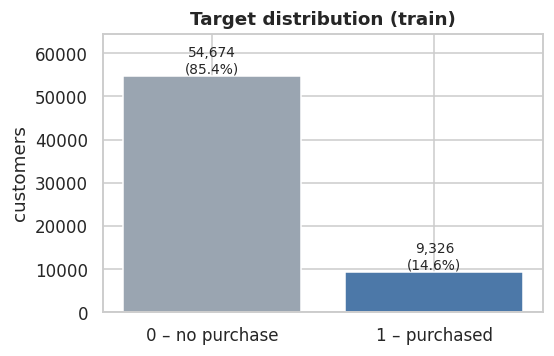

In [16]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
cnt = eda.target.value_counts().sort_index()
bars = ax.bar(["0 – no purchase", "1 – purchased"], cnt.values, color=["#9AA5B1", "#4C78A8"])
for b, v in zip(bars, cnt.values): ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(eda):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, cnt.max() * 1.18); ax.set_title("Target distribution (train)"); ax.set_ylabel("customers")
savefig("fig02_target")

**Reading:** only **14.6%** of customers purchase in the 30-day window, about 5.9 negatives per positive. A model that predicts "no purchase" for everyone would score **85.4% accuracy** while being useless. So **accuracy is the wrong headline metric**. Use precision, recall, F1 and PR-AUC (and ROC-AUC), use stratified splits/folds, and consider class weights.

### 6.2 Numeric features

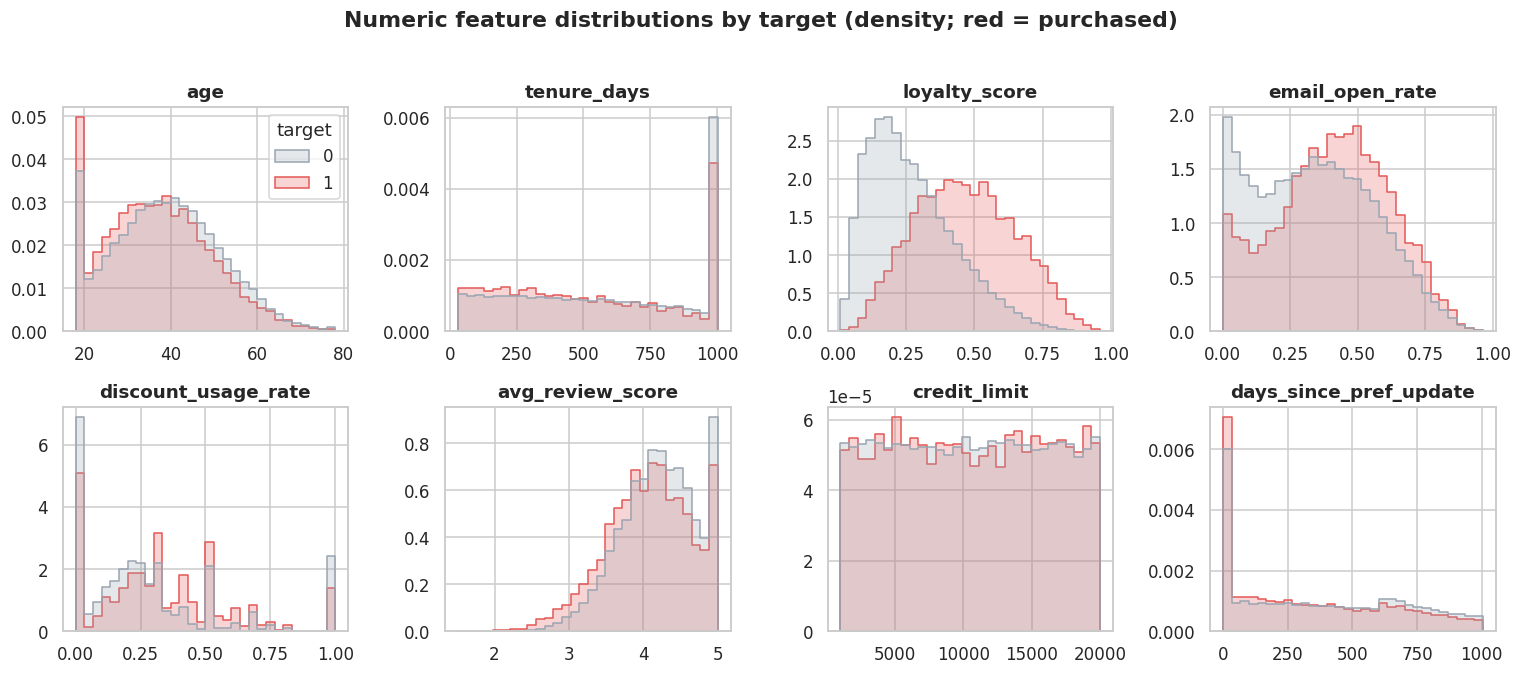

,count,mean,std,min,50%,max,skew
age,60658.0,38.308,12.290,18.000,38.000,78.000,0.27
tenure_days,64000.0,558.001,319.010,30.000,543.000,1003.000,0.03
loyalty_score,64000.0,0.299,0.175,0.009,0.268,0.961,0.73
email_open_rate,52383.0,0.354,0.214,0.000,0.352,0.963,0.17
discount_usage_rate,64000.0,0.290,0.276,0.000,0.233,1.000,1.21
avg_review_score,64000.0,4.180,0.521,1.510,4.200,5.000,-0.42
credit_limit,64000.0,10499.113,5496.800,1000.000,10502.500,19999.000,-0.00
days_since_pref_update,64000.0,379.802,307.880,0.000,346.000,1003.000,0.29


In [17]:
num_cols = ["age", "tenure_days", "loyalty_score", "email_open_rate", "discount_usage_rate", "avg_review_score", "credit_limit", "days_since_pref_update"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=eda, x=c, hue="target", stat="density", common_norm=False, element="step", bins=30, ax=ax, palette={0: "#9AA5B1", 1: "#E45756"}, legend=(c == num_cols[0]))
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Numeric feature distributions by target (density; red = purchased)", y=1.02, fontweight="bold")
savefig("fig03_numeric_by_target")

desc = eda[num_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3)
desc["skew"] = eda[num_cols].skew().round(2)
desc

**Reading:** `loyalty_score` is the standout: purchasers sit clearly to the right of non-purchasers. `email_open_rate` and `discount_usage_rate` also shift right for purchasers, while `avg_review_score` and `age` shift slightly left. `credit_limit` looks uniform between about 1,000 and 20,000 and shows no separation. `loyalty_score` is right-skewed, which matters for scaling and for linear baselines.

### 6.3 How strongly does each numeric feature predict the target on its own?

In [18]:
rows = []
for c in num_cols:
    s = eda[[c, "target"]].dropna()
    auc = roc_auc_score(s.target, s[c])
    rho = stats.spearmanr(s[c], s.target)[0]
    rows.append({"feature": c, "n_used": len(s), "single_feature_AUC": round(auc, 3), "spearman_vs_target": round(rho, 3)})
uni = pd.DataFrame(rows).sort_values("single_feature_AUC", key=lambda s: (s - 0.5).abs(), ascending=False).reset_index(drop=True)
SUMMARY["univariate"] = uni.to_dict(orient="records")
uni

,feature,n_used,single_feature_AUC,spearman_vs_target
0,loyalty_score,64000,0.795,0.360
1,email_open_rate,52383,0.591,0.113
2,discount_usage_rate,64000,0.581,0.099
3,avg_review_score,64000,0.434,-0.081
4,age,60658,0.451,-0.060
5,tenure_days,64000,0.456,-0.054
6,days_since_pref_update,64000,0.458,-0.052
7,credit_limit,64000,0.502,0.003


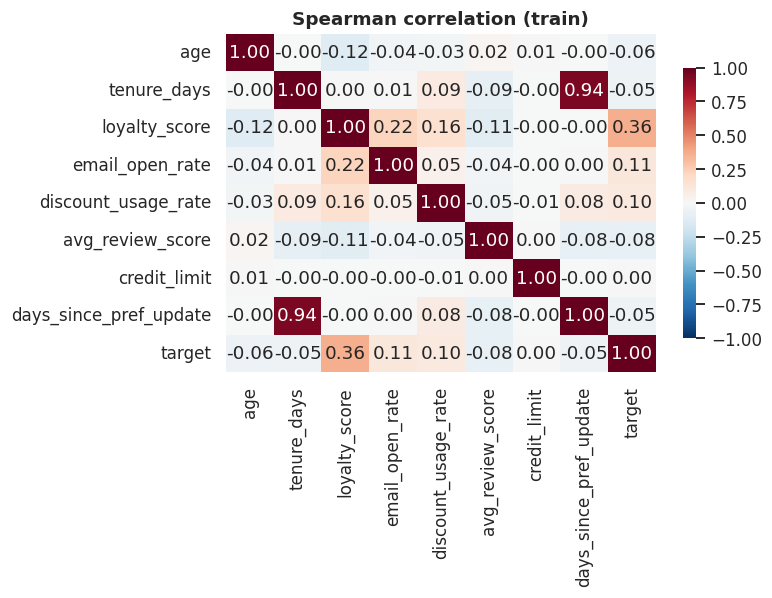

Largest |correlation| between two predictors: 0.94 (tenure_days vs days_since_pref_update)
Next largest: 0.22 (email_open_rate vs loyalty_score)


In [19]:
corr = eda[num_cols + ["target"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Spearman correlation (train)")
savefig("fig04_corr")
SUMMARY["max_feature_feature_corr"] = float(corr.drop("target").drop(columns="target").where(~np.eye(len(num_cols), dtype=bool)).abs().max().max())
pairs = corr.drop("target").drop(columns="target").where(~np.eye(len(num_cols), dtype=bool)).stack().abs().sort_values(ascending=False)
print("Largest |correlation| between two predictors: %.2f (%s)" % (pairs.iloc[0], " vs ".join(pairs.index[0])))
print("Next largest: %.2f (%s)" % (pairs.iloc[2], " vs ".join(pairs.index[2])))
SUMMARY["second_feature_corr"] = float(pairs.iloc[2])

**Reading:** `loyalty_score` is the strongest single predictor (AUC about 0.80 on its own). `email_open_rate` and `discount_usage_rate` add weaker signal (AUC about 0.58 to 0.59), while `avg_review_score`, `age`, `tenure_days` and `days_since_pref_update` carry small *inverse* signal (AUC 0.43 to 0.46: higher values mean slightly lower purchase odds). `credit_limit` is essentially random (AUC about 0.50).

**One redundancy to know about:** `tenure_days` and `days_since_pref_update` have a Spearman correlation of about **0.94**. Preference records appear to be last updated shortly after signup, so the two columns describe almost the same thing. Every other pair is below 0.25. Keep only one of the two (or combine them) in linear baselines, and expect the other to add little to a neural network.

### 6.4 Categorical features and flags

In [20]:
def rate_table(col):
    t = eda.groupby(col, observed=True).target.agg(["mean", "count"]).rename(columns={"mean": "purchase_rate"})
    return t

def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt((chi2 / n) / (min(ct.shape) - 1))

cat_cols = ["customer_tier", "country_code", "preferred_channel", "preferred_language", "email_opt_in", "sms_opt_in", "do_not_contact",
            "age_is_missing", "signup_before_history_flag", "email_open_rate_is_missing", "avg_review_was_capped",
            "referral_code_shared_flag", "pref_updated_on_cutoff_flag", "channel_consent_conflict_flag"]
cv = pd.DataFrame({"feature": cat_cols,
                   "cramers_v": [round(cramers_v(eda[c], eda.target), 3) for c in cat_cols],
                   "p_value": [stats.chi2_contingency(pd.crosstab(eda[c], eda.target))[1] for c in cat_cols]})
cv["p_value"] = cv.p_value.map(lambda p: f"{p:.1e}")
cv = cv.sort_values("cramers_v", ascending=False).reset_index(drop=True)
SUMMARY["cramers"] = cv.to_dict(orient="records")
cv

,feature,cramers_v,p_value
0,customer_tier,0.411,0.0e+00
1,email_opt_in,0.108,1.0e-164
2,channel_consent_conflict_flag,0.055,2.4e-43
3,email_open_rate_is_missing,0.037,3.2e-21
4,signup_before_history_flag,0.036,2.9e-20
5,pref_updated_on_cutoff_flag,0.028,1.0e-12
6,country_code,0.012,6.1e-02
7,preferred_language,0.011,4.3e-02
8,do_not_contact,0.007,7.6e-02
9,preferred_channel,0.006,4.8e-01


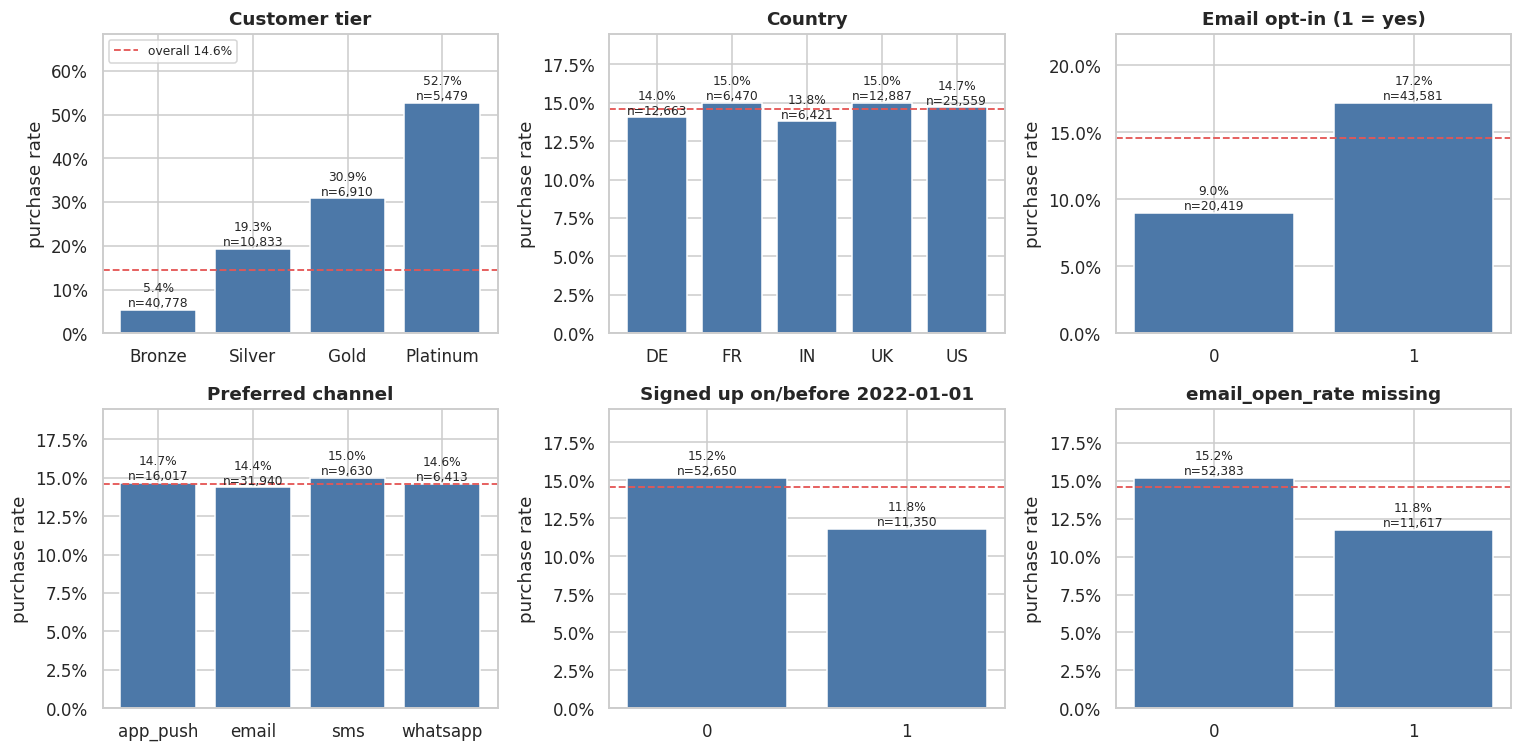

,purchase_rate,count
customer_tier,,
Bronze,0.054269,40778
Silver,0.193391,10833
Gold,0.308538,6910
Platinum,0.526738,5479


In [21]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axes.ravel(), [("customer_tier", "Customer tier"), ("country_code", "Country"), ("email_opt_in", "Email opt-in (1 = yes)"),
                                          ("preferred_channel", "Preferred channel"), ("signup_before_history_flag", "Signed up on/before 2022-01-01"),
                                          ("email_open_rate_is_missing", "email_open_rate missing")]):
    t = rate_table(col)
    ax.bar(t.index.astype(str), t.purchase_rate, color="#4C78A8")
    ax.axhline(base_rate, color="#E45756", ls="--", lw=1.2, label=f"overall {base_rate:.1%}")
    for i, (r, n) in enumerate(zip(t.purchase_rate, t["count"])): ax.text(i, r, f"{r:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, t.purchase_rate.max() * 1.3); ax.set_title(title); ax.set_ylabel("purchase rate"); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0, 0].legend(loc="upper left", fontsize=8)
savefig("fig05_rate_by_category")
rate_table("customer_tier")

**Reading:**
- **`customer_tier` is a very strong signal.** Purchase rate climbs from about 5% (Bronze) through 19% (Silver) and 31% (Gold) to **53% (Platinum)**. Caution: tier is based on 12-month spend, so it partly reflects past buying behaviour. That is legitimate (known at the cutoff) but also means it overlaps with information in the transaction tables.
- `email_opt_in` matters (17% vs 9%), but `sms_opt_in`, `preferred_channel`, `preferred_language` and `country_code` barely move the rate. The country and language numbers matter for fairness: the model should not be materially better or worse for one country.
- The consent-conflict flag shows a lower purchase rate (11.3% vs 15.7%), which is consistent with the lower rate among customers who have not opted in to email.
- **Missingness is informative.** Customers with a missing `email_open_rate` buy less (11.8% vs 15.2%), and so do the `2022-01-01` signups (11.8% vs 15.2%). This is the reason to keep the `*_is_missing` indicators rather than silently imputing, and to recreate the placeholder-signup indicator in the model (it is not saved in the CSV).

### 6.4b Review scores above 5: was capping to 5.0 reasonable?

In [22]:
rv = eda[["target", "avg_review_raw", "avg_review_was_capped"]]
groups = {
    "raw score above 5 (capped to 5.0)": rv[rv.avg_review_was_capped == 1],
    "raw score exactly 5.0":             rv[rv.avg_review_raw == 5],
    "raw score 4.5 to below 5.0":        rv[(rv.avg_review_raw >= 4.5) & (rv.avg_review_raw < 5)],
    "raw score below 4.5":               rv[rv.avg_review_raw < 4.5],
}
tbl = pd.DataFrame({k: {"customers": len(g), "purchase_rate": g.target.mean(), "approx_95%_margin": 1.96 * np.sqrt(g.target.mean() * (1 - g.target.mean()) / len(g))} for k, g in groups.items()}).T
tbl["customers"] = tbl.customers.astype(int)
display(tbl.round(3))

cap, eq5 = groups["raw score above 5 (capped to 5.0)"], groups["raw score exactly 5.0"]
ct = pd.crosstab(np.r_[np.ones(len(cap)), np.zeros(len(eq5))], np.r_[cap.target.values, eq5.target.values])
p_cap = stats.chi2_contingency(ct, correction=False)[1]
print(f"Capped group vs exactly-5.0 group: {cap.target.mean():.1%} vs {eq5.target.mean():.1%} purchase rate, chi-square p = {p_cap:.2f}")
print(f"Mean raw score among the capped values: {eda.loc[eda.avg_review_was_capped == 1, 'avg_review_raw'].mean():.2f}")
SUMMARY.update({"cap_n_train": int(len(cap)), "cap_rate": float(cap.target.mean()), "eq5_n_train": int(len(eq5)), "eq5_rate": float(eq5.target.mean()),
                "cap_vs_eq5_p": float(p_cap), "cap_raw_mean": float(eda.loc[eda.avg_review_was_capped == 1, "avg_review_raw"].mean()),
                "cap_margin": float(1.96 * np.sqrt(cap.target.mean() * (1 - cap.target.mean()) / len(cap)))})

,customers,purchase_rate,approx_95%_margin
raw score above 5 (capped to 5.0),237,0.110,0.040
raw score exactly 5.0,4296,0.117,0.010
raw score 4.5 to below 5.0,14366,0.122,0.005
raw score below 4.5,45101,0.156,0.003


Capped group vs exactly-5.0 group: 11.0% vs 11.7% purchase rate, chi-square p = 0.73
Mean raw score among the capped values: 5.80


**Reading:** the customers whose raw score was above 5 buy at about the same rate as customers who scored exactly 5.0, and the difference is not statistically distinguishable (the capped group is small, so its margin of error is about 4 points). That supports treating them as top scorers, which is what capping to 5.0 does. Setting them to missing and median-imputing (about 4.2) would place them mid-scale instead.

**The trade-off:** capping is an imputation done inside the file, and without a flag the 313 affected customers (0.4% of rows) cannot be told apart afterwards. The effect on a model is expected to be very small, but it is a deliberate departure from "impute only in the pipeline". It is recorded in the cleaning log.

### 6.5 Loyalty score, tenure and the 100 regions

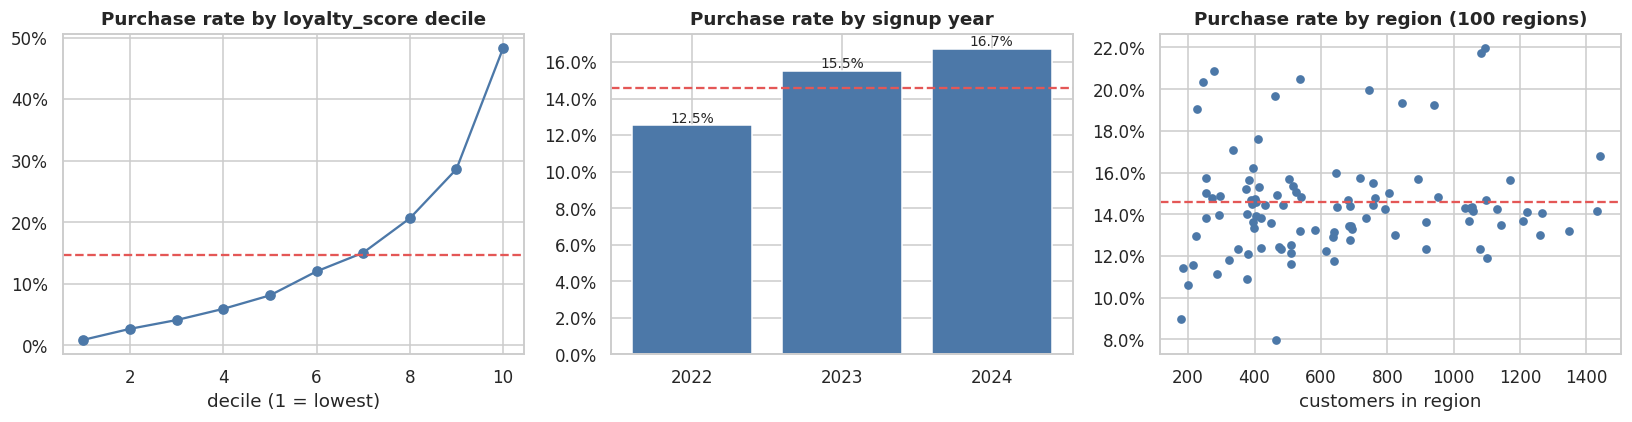

Regions: min n=178, max n=1442, purchase-rate range 8.0% to 22.0%
Region vs target: chi-square p=1.1e-21, Cramer's V=0.068 | observed SD of region rates=0.025 vs 0.014 expected from chance alone


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
q = eda.groupby(pd.qcut(eda.loyalty_score, 10), observed=True).target.mean()
axes[0].plot(range(1, 11), q.values, marker="o", color="#4C78A8"); axes[0].axhline(base_rate, color="#E45756", ls="--")
axes[0].set_title("Purchase rate by loyalty_score decile"); axes[0].set_xlabel("decile (1 = lowest)"); axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

y = eda.groupby(eda.signup_date.dt.year).target.agg(["mean", "count"])
axes[1].bar(y.index.astype(str), y["mean"], color="#4C78A8"); axes[1].axhline(base_rate, color="#E45756", ls="--")
for i, (r, n) in enumerate(zip(y["mean"], y["count"])): axes[1].text(i, r, f"{r:.1%}", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Purchase rate by signup year"); axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

rg = eda.groupby("region").target.agg(["mean", "count"])
axes[2].scatter(rg["count"], rg["mean"], color="#4C78A8", s=22); axes[2].axhline(base_rate, color="#E45756", ls="--")
axes[2].set_title("Purchase rate by region (100 regions)"); axes[2].set_xlabel("customers in region"); axes[2].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
savefig("fig06_loyalty_tenure_region")
print("Regions: min n=%d, max n=%d, purchase-rate range %.1f%% to %.1f%%" % (rg["count"].min(), rg["count"].max(), rg["mean"].min()*100, rg["mean"].max()*100))
ct_r = pd.crosstab(eda.region, eda.target); chi_r = stats.chi2_contingency(ct_r)
exp_sd = np.sqrt(base_rate * (1 - base_rate) / ct_r.sum(axis=1).mean())
print("Region vs target: chi-square p=%.1e, Cramer's V=%.3f | observed SD of region rates=%.3f vs %.3f expected from chance alone" % (chi_r[1], np.sqrt(chi_r[0] / ct_r.values.sum()), rg["mean"].std(), exp_sd))
SUMMARY["region_chi_p"] = float(chi_r[1]); SUMMARY["region_v"] = float(np.sqrt(chi_r[0] / ct_r.values.sum()))
SUMMARY["region_sd_obs"] = float(rg["mean"].std()); SUMMARY["region_sd_exp"] = float(exp_sd)
SUMMARY["region_rate_min"] = float(rg["mean"].min()); SUMMARY["region_rate_max"] = float(rg["mean"].max())
SUMMARY["loyalty_decile_low"] = float(q.iloc[0]); SUMMARY["loyalty_decile_high"] = float(q.iloc[-1])

**Reading:** the loyalty relationship is steep and monotonic (the top decile buys at several times the base rate and the bottom decile almost never). Newer signups buy more (12.5% for 2022 vs 16.7% for 2024); part of the 2022 gap comes from the left-censored `2022-01-01` group. **Region carries real signal:** regional purchase rates range from about 8% to 22%, and the spread (standard deviation about 2.5 points) is almost double what chance alone would give with roughly 640 customers per region (about 1.4 points). A chi-square test confirms it (p < 1e-20, Cramér's V about 0.07). Because there are 100 regions, avoid raw one-hot encoding; use a learned embedding or regularised target encoding fitted inside cross-validation.

### 6.6 Do the `noise_customer_*` columns carry any signal?

In [24]:
nz = [f"noise_customer_{i}" for i in range(5)]
rows = []
for c in nz:
    rows.append({"feature": c, "mean": round(float(eda[c].mean()), 3), "std": round(float(eda[c].std()), 3), "spearman_vs_target": round(stats.spearmanr(eda[c], eda.target)[0], 4),
                 "single_feature_AUC": round(roc_auc_score(eda.target, eda[c]), 3),
                 "mannwhitney_p": round(stats.mannwhitneyu(eda.loc[eda.target == 1, c], eda.loc[eda.target == 0, c]).pvalue, 3)})
noise_tbl = pd.DataFrame(rows); SUMMARY["noise"] = noise_tbl.to_dict(orient="records")
noise_tbl

,feature,mean,std,spearman_vs_target,single_feature_AUC,mannwhitney_p
0,noise_customer_0,-0.002,0.998,0.0002,0.500,0.968
1,noise_customer_1,0.007,0.999,-0.0014,0.499,0.724
2,noise_customer_2,-0.003,1.002,0.0029,0.502,0.463
3,noise_customer_3,0.006,1.005,0.0098,0.508,0.013
4,noise_customer_4,-0.003,0.999,-0.0040,0.497,0.309


**Conclusion:** all five are standard-normal-looking, with correlation and AUC indistinguishable from chance (AUC 0.50 to 0.51). `noise_customer_3` has a nominal p-value of 0.013, but its effect is negligible (Spearman 0.01) and it does not pass a Bonferroni correction for five tests (threshold 0.01), so it is consistent with chance. They match the README's description ("no business meaning"), so we **drop them from the saved cleaned file** (set `KEEP_NOISE_COLUMNS = True` to keep them). Dropping them reduces overfitting risk, and the notebook documents why.

### 6.7 Possible leakage and spurious signals

In [25]:
auc_id = roc_auc_score(eda.target, eda.customer_id)
rho_id = stats.spearmanr(eda.customer_id, eda.target)[0]
print(f"customer_id vs target: AUC={auc_id:.3f}, Spearman={rho_id:.4f}  -> ID order carries no signal")
print("Max signup_date:", eda.signup_date.max().date(), "| Max last_updated:", eda.last_updated.max().date(), "| cutoff:", CUTOFF.date())
print("Every date field is on or before the cutoff, so no feature was recorded inside the prediction window (1 to 30 Oct 2024).")

lq = eda.groupby(eda.last_updated.dt.to_period("Q")).target.agg(["mean", "count"])
display(lq.round(3).T)
SUMMARY["id_auc"] = float(auc_id)

customer_id vs target: AUC=0.497, Spearman=-0.0033  -> ID order carries no signal
Max signup_date: 2024-08-31 | Max last_updated: 2024-09-30 | cutoff: 2024-09-30
Every date field is on or before the cutoff, so no feature was recorded inside the prediction window (1 to 30 Oct 2024).


last_updated,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3
mean,0.114,0.121,0.118,0.123,0.135,0.136,0.149,0.144,0.156,0.168,0.166
count,2857.000,3488.000,4536.000,5615.000,4991.000,4491.000,4973.000,5191.000,5433.000,5539.000,16886.000


**Reading:** `customer_id` is not informative (AUC 0.50), so IDs can be dropped as a feature. All date fields are on or before the cutoff. Purchase rate rises with the year of the preference update (12.0% for 2022 vs 16.4% for 2024). Because `last_updated` tracks signup date closely (section 6.3), this mostly repeats the "newer customers buy more" pattern rather than adding new information. It is legitimate because it is known at the cutoff, but treat `days_since_pref_update` and `pref_updated_on_cutoff_flag` as low-priority features and check them with feature-importance tests.

### 6.8 Customer preferences

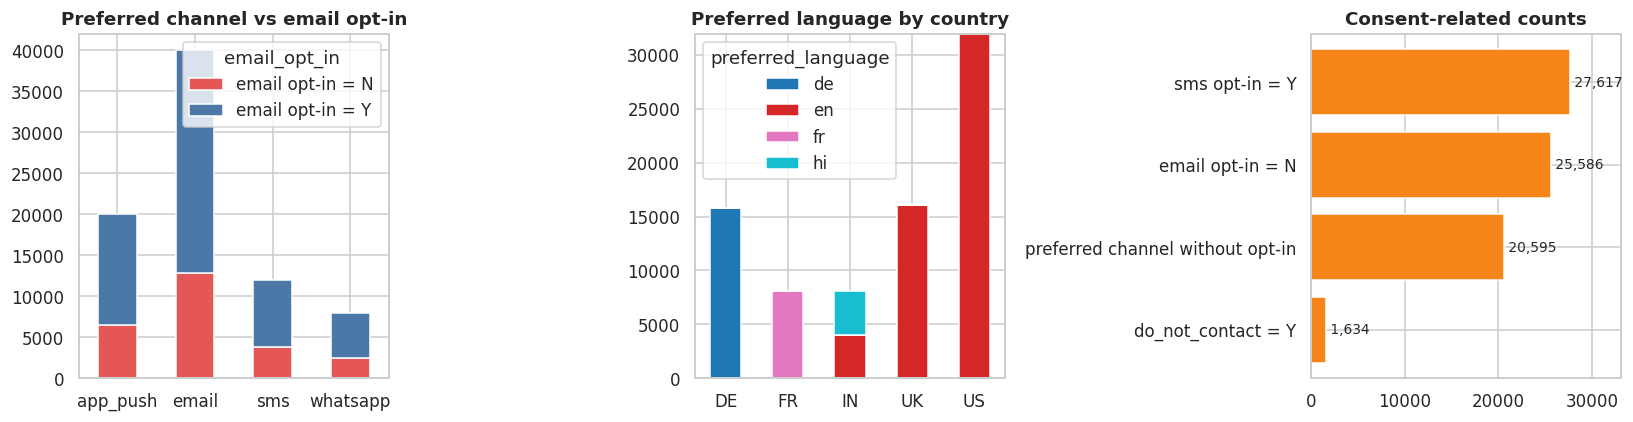

preferred_language,de,en,fr,hi
country_code,,,,
DE,15822,0,0,0
FR,0,0,8096,0
IN,0,3997,0,4054
UK,0,16075,0,0
US,0,31956,0,0


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ct = pd.crosstab(preferences.preferred_channel, preferences.email_opt_in.map({0: "email opt-in = N", 1: "email opt-in = Y"}))
ct.plot(kind="bar", stacked=True, ax=axes[0], color=["#E45756", "#4C78A8"]); axes[0].set_title("Preferred channel vs email opt-in"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
cl = pd.crosstab(customers.set_index("customer_id").country_code, preferences.set_index("customer_id").preferred_language)
cl.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10"); axes[1].set_title("Preferred language by country"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
flag_counts = pd.Series({"do_not_contact = Y": preferences.do_not_contact.sum(), "preferred channel without opt-in": preferences_eda.channel_consent_conflict_flag.sum(),
                         "email opt-in = N": (preferences.email_opt_in == 0).sum(), "sms opt-in = Y": preferences.sms_opt_in.sum()})
axes[2].barh(flag_counts.index, flag_counts.values, color="#F58518"); axes[2].set_title("Consent-related counts")
for i, v in enumerate(flag_counts.values): axes[2].text(v, i, f" {v:,}", va="center", fontsize=9)
axes[2].set_xlim(0, flag_counts.max() * 1.2)
savefig("fig07_preferences")
display(pd.crosstab(customers.set_index("customer_id").country_code, preferences.set_index("customer_id").preferred_language))

**Reading:** language follows country exactly (DE → `de`, FR → `fr`, UK/US → `en`), except **India**, which splits between English and Hindi (about 50/50). That matters for **W8** (messages in the customer's preferred language): India needs Hindi, and `preferred_language` should be used rather than inferred from country. The consent mismatch from section 3.4 is also visible in the left chart.

## 7. Train vs test: is the test set from the same distribution?
If train and test differ, a model that scores well in validation may score worse on test. We compare feature distributions with a Kolmogorov–Smirnov test (numeric) and a chi-square test (categorical). With 64,000 and 16,000 rows, tiny differences can be "significant", so we also report the effect size.

In [27]:
full = pd.concat([train.assign(split="train"), test.assign(split="test")]).merge(customers_eda, on="customer_id").merge(preferences_eda, on="customer_id")
rows = []
for c in num_cols:
    a, b = full.loc[full.split == "train", c].dropna(), full.loc[full.split == "test", c].dropna()
    ks = stats.ks_2samp(a, b); rows.append({"feature": c, "type": "numeric", "effect_size": round(ks.statistic, 4), "p_value": round(ks.pvalue, 3)})
for c in ["customer_tier", "country_code", "preferred_channel", "preferred_language", "email_opt_in", "email_open_rate_is_missing", "signup_before_history_flag", "channel_consent_conflict_flag"]:
    ct = pd.crosstab(full[c], full.split); chi = stats.chi2_contingency(ct)
    rows.append({"feature": c, "type": "categorical", "effect_size": round(np.sqrt(chi[0] / ct.values.sum() / (min(ct.shape) - 1)), 4), "p_value": round(chi[1], 3)})
shift = pd.DataFrame(rows); SUMMARY["shift"] = shift.to_dict(orient="records")
print("effect_size = KS statistic (numeric) or Cramér's V (categorical); values below ~0.02 are negligible")
shift

effect_size = KS statistic (numeric) or Cramér's V (categorical); values below ~0.02 are negligible


,feature,type,effect_size,p_value
0,age,numeric,0.0072,0.543
1,tenure_days,numeric,0.0047,0.935
2,loyalty_score,numeric,0.0037,0.994
3,email_open_rate,numeric,0.0085,0.430
4,discount_usage_rate,numeric,0.0059,0.767
5,avg_review_score,numeric,0.0060,0.747
6,credit_limit,numeric,0.0122,0.043
7,days_since_pref_update,numeric,0.0073,0.498
8,customer_tier,categorical,0.0104,0.035
9,country_code,categorical,0.0028,0.958


**Reading:** all effect sizes are tiny (the largest is about 0.012). Two tests are nominally significant at 0.05 (`credit_limit` p≈0.04 and `customer_tier` p≈0.035), but with 16 tests about one false positive is expected by chance, and the effect sizes are negligible. Test looks like a random split of the same population, so validation scores on train should be a fair guide to test performance.

## 8. Save cleaned data and summary
Cleaned files go to `OUT_DIR`; the raw data pack is untouched. Dates are written as ISO strings, indicators as 0/1, and missing values as empty cells so they read back as NaN. The saved files contain **no EDA-only helper columns**.

In [28]:
customers_out = customers if KEEP_NOISE_COLUMNS else customers.drop(columns=[c for c in customers if c.startswith("noise_")])
customers_out = customers_out.assign(customer_tier=customers_out.customer_tier.astype(str))

customers_out.to_csv(os.path.join(OUT_DIR, "customers_clean.csv"), index=False)
preferences.to_csv(os.path.join(OUT_DIR, "customer_preferences_clean.csv"), index=False)
train.to_csv(os.path.join(OUT_DIR, "train_clean.csv"), index=False)
test.to_csv(os.path.join(OUT_DIR, "test_clean.csv"), index=False)
cleaning_log.to_csv(os.path.join(OUT_DIR, "cleaning_log.csv"), index=False)
SUMMARY["cleaning_log"] = cleaning_log.to_dict(orient="records")
SUMMARY["customers_clean_cols"] = list(customers_out.columns)
SUMMARY["prefs_clean_cols"] = list(preferences.columns)
with open(os.path.join(OUT_DIR, "eda_summary.json"), "w") as f:
    json.dump(SUMMARY, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

for fn in ["customers_clean.csv", "customer_preferences_clean.csv", "train_clean.csv", "test_clean.csv", "cleaning_log.csv"]:
    d = pd.read_csv(os.path.join(OUT_DIR, fn)); print(f"{fn:34s} {d.shape[0]:>7,} rows x {d.shape[1]:>2} cols")

customers_clean.csv                 80,000 rows x 14 cols
customer_preferences_clean.csv      80,000 rows x  7 cols
train_clean.csv                     64,000 rows x  2 cols
test_clean.csv                      16,000 rows x  1 cols
cleaning_log.csv                        14 rows x  6 cols


### How to use the cleaned files in modelling
```python
df = (train_clean.merge(customers_clean, on="customer_id", validate="1:1")
                 .merge(customer_preferences_clean, on="customer_id", validate="1:1"))
```
- The saved files hold only the cleaned columns. **Features such as `tenure_days` are not saved**; derive them yourself from the cleaned columns, for example `tenure_days = (pd.Timestamp("2024-09-30") - signup_date).dt.days`, then drop `signup_date`, `last_updated`, `customer_id` and `referral_code`.
- Other quantities used in this EDA can be recreated the same way if the model needs them: `signup_date == "2022-01-01"` (placeholder signups), `last_updated == "2024-09-30"`, and a consent-conflict indicator (preferred channel email or SMS without the matching opt-in). See section 6.0.
- `tenure_days` and `days_since_pref_update` are about 0.94 correlated; keep one (or combine) for linear baselines.
- Split first, then **impute inside a `Pipeline`/`ColumnTransformer`** (median for `age` and `email_open_rate`), fitted on the training fold only. `age_is_missing` and `email_open_rate_is_missing` carry the missingness information. `avg_review_score` has no missing values (scores above 5 were capped to 5.0).
- Use stratified splits and report precision, recall, F1 and PR-AUC, not accuracy alone.
- Compare the deep model against a non-deep baseline (e.g. logistic regression or gradient boosting), as the project brief requires.